# Wellness Tourism Package — Purchase Prediction

**Visit with Us** is adding a Wellness Tourism Package and needs to decide whom to contact. Contacting every customer is slow and wastes sales effort: only about 19% of customers in the registered file purchase a package. This notebook builds an MLOps pipeline that scores a customer before outreach.

The scored target is `ProdTaken` (1 = purchased, 0 = did not). The pipeline registers the dataset, cleans it, writes a stratified train/test split, tunes five model families, logs every tuned parameter set, and saves the best model for a Streamlit app. GitHub Actions runs those steps and pushes the chosen model back to `main`.


## 1. Data registration

The raw file lives at `data/tourism.csv`. Registration checks that every expected column is present, then prints the row count, missing-value counts, and the purchase split. A failed column check stops the workflow before preparation or training.


In [1]:
from pathlib import Path
import json
import sys

import pandas as pd

PROJECT_ROOT = Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.validate_data import print_summary, validate_dataset

frame, registration = validate_dataset(PROJECT_ROOT / "data" / "tourism.csv")
print_summary(registration)
frame.head()


Dataset registration summary
Path: /Users/kavita.kanthaliya/Documents/Github-SF-BT/BT_OrgESC_Asset_Management/wellness_tourism_mlops/data/tourism.csv
Rows: 4128
Columns: 21
Expected columns: present
Missing values by column:
  Unnamed: 0: 0
  CustomerID: 0
  ProdTaken: 0
  Age: 0
  TypeofContact: 0
  CityTier: 0
  DurationOfPitch: 0
  Occupation: 0
  Gender: 0
  NumberOfPersonVisiting: 0
  NumberOfFollowups: 0
  ProductPitched: 0
  PreferredPropertyStar: 0
  MaritalStatus: 0
  NumberOfTrips: 0
  Passport: 0
  PitchSatisfactionScore: 0
  OwnCar: 0
  NumberOfChildrenVisiting: 0
  Designation: 0
  MonthlyIncome: 0
Target counts (ProdTaken):
  0: 3331
  1: 797
Purchase rate: 0.1931
Duplicate rows: 0


,Unnamed: 0,CustomerID,ProdTaken,Age,TypeofContact,CityTier,DurationOfPitch,Occupation,Gender,NumberOfPersonVisiting,...,ProductPitched,PreferredPropertyStar,MaritalStatus,NumberOfTrips,Passport,PitchSatisfactionScore,OwnCar,NumberOfChildrenVisiting,Designation,MonthlyIncome
0,0,200000,1,41.0,Self Enquiry,3,6.0,Salaried,Female,3,...,Deluxe,3.0,Single,1.0,1,2,1,0.0,Manager,20993.0
1,1,200001,0,49.0,Company Invited,1,14.0,Salaried,Male,3,...,Deluxe,4.0,Divorced,2.0,0,3,1,2.0,Manager,20130.0
2,2,200002,1,37.0,Self Enquiry,1,8.0,Free Lancer,Male,3,...,Basic,3.0,Single,7.0,1,3,0,0.0,Executive,17090.0
3,3,200003,0,33.0,Company Invited,1,9.0,Salaried,Female,2,...,Basic,3.0,Divorced,2.0,1,5,1,1.0,Executive,17909.0
4,5,200005,0,32.0,Company Invited,1,8.0,Salaried,Male,3,...,Basic,3.0,Single,1.0,0,5,1,1.0,Executive,18068.0


### Registration notes

The registered file has 4,128 rows and 21 columns. There are no missing values, so imputation is not required. `ProdTaken` is imbalanced: 3,331 customers did not buy (80.7%) and 797 did (19.3%). A model that always predicts "no purchase" would be about 81% accurate and would never find a buyer, so accuracy alone is the wrong selection metric. ROC-AUC is used later because it scores how well the model ranks likely buyers.


## 2. Data preparation

Preparation loads `data/tourism.csv` from this repository, cleans it, drops columns that cannot help a new customer score, and writes a stratified 80/20 split to `data/processed/`. The GitHub Actions job uploads that folder as the `processed-data` artifact. The training job reads the artifact rather than rebuilding the split.


In [2]:
from src.prepare_data import prepare_dataset, print_summary as print_prepare_summary

train, test, preparation = prepare_dataset(PROJECT_ROOT / "data" / "tourism.csv")
print_prepare_summary(preparation)
print("Train columns:", list(train.columns))
train.head()


Data preparation summary
Rows registered: 4128
Gender labels corrected (Fe Male -> Female): 155
Columns dropped: Unnamed: 0, CustomerID, Designation
Duplicate rows removed: 117
Train rows: 3208 (purchase rate 0.1930)
Test rows: 803 (purchase rate 0.1930)
Clip bounds learned from the training split:
  DurationOfPitch: 6.00 to 35.00
  NumberOfTrips: 1.00 to 8.00
  MonthlyIncome: 16601.00 to 34246.00
Saved /Users/kavita.kanthaliya/Documents/Github-SF-BT/BT_OrgESC_Asset_Management/wellness_tourism_mlops/data/processed/train.csv
Saved /Users/kavita.kanthaliya/Documents/Github-SF-BT/BT_OrgESC_Asset_Management/wellness_tourism_mlops/data/processed/test.csv
Train columns: ['ProdTaken', 'Age', 'TypeofContact', 'CityTier', 'DurationOfPitch', 'Occupation', 'Gender', 'NumberOfPersonVisiting', 'NumberOfFollowups', 'ProductPitched', 'PreferredPropertyStar', 'MaritalStatus', 'NumberOfTrips', 'Passport', 'PitchSatisfactionScore', 'OwnCar', 'NumberOfChildrenVisiting', 'MonthlyIncome']


,ProdTaken,Age,TypeofContact,CityTier,DurationOfPitch,Occupation,Gender,NumberOfPersonVisiting,NumberOfFollowups,ProductPitched,PreferredPropertyStar,MaritalStatus,NumberOfTrips,Passport,PitchSatisfactionScore,OwnCar,NumberOfChildrenVisiting,MonthlyIncome
0,0,31.0,Self Enquiry,1,17.0,Salaried,Male,2,3.0,Basic,3.0,Divorced,4.0,1,3,1,1.0,17356.0
1,1,38.0,Self Enquiry,1,18.0,Small Business,Female,4,6.0,Deluxe,4.0,Divorced,7.0,0,4,1,1.0,23455.0
2,0,28.0,Self Enquiry,1,13.0,Salaried,Male,3,5.0,Basic,3.0,Divorced,3.0,0,2,1,2.0,21217.0
3,0,37.0,Self Enquiry,1,20.0,Salaried,Female,3,3.0,Basic,5.0,Married,2.0,0,4,1,0.0,18034.0
4,0,46.0,Self Enquiry,3,27.0,Salaried,Female,3,4.0,Deluxe,3.0,Unmarried,2.0,0,1,1,1.0,23528.0


### What was removed, and why

- `Unnamed: 0` is a row index from the export.
- `CustomerID` identifies a person. It is unique per row, so a model can memorise it and it is unknown in a useful way for a new prospect.
- `Designation` matches `ProductPitched` exactly (Executive with Basic, Manager with Deluxe, Senior Manager with Standard, AVP with Super Deluxe, VP with King). Keeping both would double-count the same information.
- 155 gender values are stored as `Fe Male`. They are corrected to `Female`.
- 117 rows are exact duplicates once the identifier columns are gone. They are removed so the same customer cannot land in both the train and test sets.
- `DurationOfPitch`, `NumberOfTrips`, and `MonthlyIncome` have a few extreme values (a 127-minute pitch, 22 trips, income of 1,000 and of 98,678). Bounds are the 1st and 99th percentiles of the **training** split, then applied to both splits. The test set does not influence the bounds.

The split is stratified, so both sets keep a 19.3% purchase rate (3,208 train rows and 803 test rows).


## 3. Who buys, before the model

These rates use the cleaned training table. They are the patterns the sales team can act on even before looking at a score.


In [3]:
profile = train.copy()
print("Purchase rate by passport")
display(profile.groupby("Passport")["ProdTaken"].agg(customers="count", purchase_rate="mean").round(3))
print("Purchase rate by product pitched")
display(profile.groupby("ProductPitched")["ProdTaken"].agg(customers="count", purchase_rate="mean").sort_values("purchase_rate", ascending=False).round(3))
print("Purchase rate by marital status")
display(profile.groupby("MaritalStatus")["ProdTaken"].agg(customers="count", purchase_rate="mean").sort_values("purchase_rate", ascending=False).round(3))
print("Purchase rate by city tier")
display(profile.groupby("CityTier")["ProdTaken"].agg(customers="count", purchase_rate="mean").round(3))
print("Purchase rate by type of contact")
display(profile.groupby("TypeofContact")["ProdTaken"].agg(customers="count", purchase_rate="mean").round(3))


Purchase rate by passport


,customers,purchase_rate
Passport,,
0,2261,0.123
1,947,0.361


Purchase rate by product pitched


,customers,purchase_rate
ProductPitched,,
Basic,1257,0.303
Standard,569,0.156
Deluxe,1128,0.119
King,76,0.066
Super Deluxe,178,0.056


Purchase rate by marital status


,customers,purchase_rate
MaritalStatus,,
Single,510,0.380
Unmarried,528,0.241
Married,1535,0.144
Divorced,635,0.121


Purchase rate by city tier


,customers,purchase_rate
CityTier,,
1,2074,0.163
2,126,0.286
3,1008,0.242


Purchase rate by type of contact


,customers,purchase_rate
TypeofContact,,
Company Invited,929,0.220
Self Enquiry,2279,0.182


### Segment notes

Passport holders buy far more often than customers without a passport (about 36% versus about 12% in the full file). Basic packages and single customers are the next strongest groups. Married and divorced customers sit near 13–14%. Company-invited contacts convert a little higher than self-enquiry. Tier 1 cities are the largest group and the lowest conversion group. Owning a car barely changes the purchase rate, so it is a weak targeting rule on its own. These gaps are large enough that a useful model should rank passport, product, and marital status near the top, and the campaign should not treat every city tier as equal.


## 4. Model building and experiment tracking

The training job loads `train.csv` and `test.csv` from the workflow artifact (`data/processed` locally). Each candidate is a scikit-learn pipeline: one-hot encoding for the five categorical fields, then the classifier. Numeric fields are left as they are because the trees do not need scaling.

Five families from the allowed list are tuned with a grid search and 3-fold stratified cross-validation:

- Decision tree, with `class_weight='balanced'`
- Random forest, with `class_weight='balanced'`
- AdaBoost
- Gradient boosting
- XGBoost, with `scale_pos_weight` set to the train-set ratio of non-buyers to buyers

The selection metric is cross-validated ROC-AUC on the training split. Test metrics are reported after the choice is made. Every winning parameter set is written to `reports/experiment_log.json`, and the best pipeline is saved to `models/best_model.joblib`.


In [4]:
from src.train_model import train_models

experiments, metadata = train_models()
experiment_table = pd.DataFrame(experiments).sort_values("cv_roc_auc", ascending=False)
experiment_table = experiment_table.round(4)
display(experiment_table)
print("Selected model:", metadata["best_model"])
print("Tuned parameters:", json.dumps(metadata["best_params"], indent=2))
print("Held-out test metrics:", json.dumps(metadata["test_metrics"], indent=2))


decision_tree: cv_roc_auc=0.8191 test_roc_auc=0.8439 test_f1=0.5547 params={'model__max_depth': 8, 'model__min_samples_leaf': 20}


random_forest: cv_roc_auc=0.9225 test_roc_auc=0.9477 test_f1=0.7126 params={'model__max_depth': 14, 'model__min_samples_leaf': 2, 'model__n_estimators': 150}


adaboost: cv_roc_auc=0.8221 test_roc_auc=0.8028 test_f1=0.3768 params={'model__learning_rate': 1.0, 'model__n_estimators': 100}


gradient_boosting: cv_roc_auc=0.8690 test_roc_auc=0.8593 test_f1=0.5294 params={'model__learning_rate': 0.1, 'model__max_depth': 3, 'model__n_estimators': 100}


xgboost: cv_roc_auc=0.9098 test_roc_auc=0.9202 test_f1=0.7604 params={'model__learning_rate': 0.1, 'model__max_depth': 5, 'model__n_estimators': 150}
Best model: random_forest
Logged tuned parameters to /Users/kavita.kanthaliya/Documents/Github-SF-BT/BT_OrgESC_Asset_Management/wellness_tourism_mlops/reports/experiment_log.json
Saved model to /Users/kavita.kanthaliya/Documents/Github-SF-BT/BT_OrgESC_Asset_Management/wellness_tourism_mlops/models/best_model.joblib


,model,best_params,cv_roc_auc,test_roc_auc,test_f1,test_recall,test_precision,test_accuracy
1,random_forest,"{'model__max_depth': 14, 'model__min_samples_l...",0.9225,0.9477,0.7126,0.6000,0.8774,0.9066
4,xgboost,"{'model__learning_rate': 0.1, 'model__max_dept...",0.9098,0.9202,0.7604,0.7677,0.7532,0.9066
3,gradient_boosting,"{'model__learning_rate': 0.1, 'model__max_dept...",0.8690,0.8593,0.5294,0.4065,0.7590,0.8605
2,adaboost,"{'model__learning_rate': 1.0, 'model__n_estima...",0.8221,0.8028,0.3768,0.2516,0.7500,0.8394
0,decision_tree,"{'model__max_depth': 8, 'model__min_samples_le...",0.8191,0.8439,0.5547,0.7355,0.4453,0.7721


Selected model: random_forest
Tuned parameters: {
  "model__max_depth": 14,
  "model__min_samples_leaf": 2,
  "model__n_estimators": 150
}
Held-out test metrics: {
  "roc_auc": 0.9477299880525687,
  "f1": 0.7126436781609196,
  "recall": 0.6,
  "precision": 0.8773584905660378,
  "accuracy": 0.9066002490660025
}


### Model notes

Random forest wins the pre-declared rule, cross-validated ROC-AUC (about 0.923), and it also has the highest test ROC-AUC (about 0.948). At the default 0.5 cutoff its test precision is about 0.88 and its recall is 0.60: most customers it flags do buy, and it misses about 40% of buyers.

XGBoost is second on ROC-AUC (about 0.910) and has the highest test F1 (about 0.76), with recall about 0.77. If the sales team would rather miss fewer buyers and can afford more contacts, the logged XGBoost run is the alternative. The saved model stays the random forest because the selection rule was fixed before looking at the test set, and because ROC-AUC is the right measure when the contact list is a ranking rather than a single yes/no at 0.5.

AdaBoost is the weakest of the five on this file. A single decision tree ranks customers reasonably (test ROC-AUC about 0.84) but its precision at 0.5 is only about 0.45, so a large share of the people it would contact would not buy.


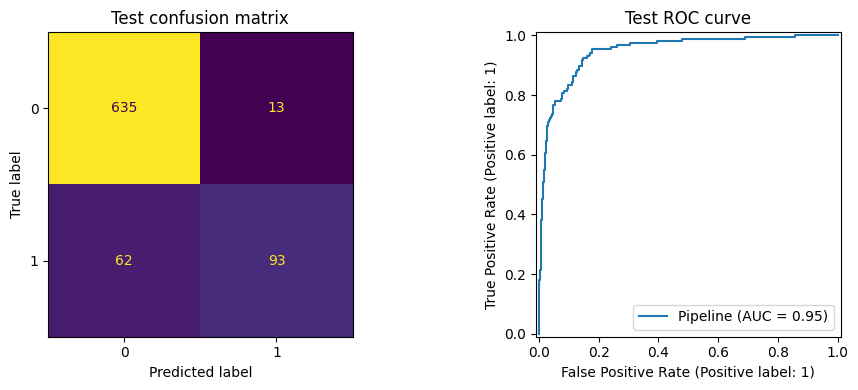

,feature,importance
17,numeric__Age,0.1156
28,numeric__MonthlyIncome,0.1079
24,numeric__Passport,0.1042
19,numeric__DurationOfPitch,0.0916
23,numeric__NumberOfTrips,0.0552
25,numeric__PitchSatisfactionScore,0.0536
21,numeric__NumberOfFollowups,0.0482
8,categorical__ProductPitched_Basic,0.0465
22,numeric__PreferredPropertyStar,0.0411
18,numeric__CityTier,0.0398


In [5]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay
import joblib

model = joblib.load(PROJECT_ROOT / "models" / "best_model.joblib")
features = [column for column in test.columns if column != "ProdTaken"]
x_test = test[features]
y_test = test["ProdTaken"]

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay.from_estimator(model, x_test, y_test, ax=axes[0], colorbar=False)
axes[0].set_title("Test confusion matrix")
RocCurveDisplay.from_estimator(model, x_test, y_test, ax=axes[1])
axes[1].set_title("Test ROC curve")
fig.tight_layout()
plt.show()

preprocessor = model.named_steps["preprocessor"]
importances = model.named_steps["model"].feature_importances_
names = preprocessor.get_feature_names_out()
importance = (
    pd.DataFrame({"feature": names, "importance": importances})
    .sort_values("importance", ascending=False)
    .head(12)
)
display(importance.round(4))


### How to use the score

Rank customers by predicted probability and contact from the top of the list until the team's weekly capacity is used. The 0.5 cutoff is a conservative setting: it keeps precision high. Lowering the cutoff contacts more people and raises recall. Passport, the Basic product, and single status are the customer traits the rate tables already flag; the model combines those with pitch length, follow-ups, age, and income instead of applying one rule at a time.

Free Lancer appears on only two rows. That occupation should not drive a campaign rule.


## 5. Model deployment

`app.py` is the Streamlit application. It loads `models/best_model.joblib` and `models/model_metadata.json`, collects the customer fields in a form, stores that form in a one-row dataframe, and scores the dataframe. `requirements.txt` is the dependency file Streamlit Community Cloud installs, and `runtime.txt` pins Python 3.11 so the cloud environment matches the training environment.

Deployment steps on Streamlit Community Cloud:

1. Push this repository to a public GitHub repository.
2. Create a new app at [share.streamlit.io](https://share.streamlit.io) from that repository.
3. Set the main file to `app.py`.
4. Put the public app URL in the links section below.

The problem statement also mentions a Hugging Face Space. The graded deployment in the rubric is Streamlit Community Cloud, so that is the app this repository is set up to run.


In [6]:
app_source = (PROJECT_ROOT / "app.py").read_text().splitlines()
print(f"app.py is present ({len(app_source)} lines).")
print("Dependency file:", (PROJECT_ROOT / "requirements.txt").read_text())
sample = pd.DataFrame([{
    "Age": 30,
    "TypeofContact": "Company Invited",
    "CityTier": 3,
    "DurationOfPitch": 15.0,
    "Occupation": "Large Business",
    "Gender": "Male",
    "NumberOfPersonVisiting": 3,
    "NumberOfFollowups": 5.0,
    "ProductPitched": "Basic",
    "PreferredPropertyStar": 5.0,
    "MaritalStatus": "Single",
    "NumberOfTrips": 2.0,
    "Passport": 1,
    "PitchSatisfactionScore": 5,
    "OwnCar": 0,
    "NumberOfChildrenVisiting": 0.0,
    "MonthlyIncome": 21000.0,
}])
sample = sample[metadata["feature_columns"]]
print("Input dataframe passed to the model:")
display(sample)
print("Predicted class:", int(model.predict(sample)[0]))
print("Purchase probability:", round(float(model.predict_proba(sample)[0, 1]), 4))


app.py is present (119 lines).
Dependency file: pandas==2.3.3
numpy==2.0.2
scikit-learn==1.6.1
xgboost==2.1.4
joblib==1.5.3
streamlit==1.50.0
matplotlib==3.9.4

Input dataframe passed to the model:


,Age,TypeofContact,CityTier,DurationOfPitch,Occupation,Gender,NumberOfPersonVisiting,NumberOfFollowups,ProductPitched,PreferredPropertyStar,MaritalStatus,NumberOfTrips,Passport,PitchSatisfactionScore,OwnCar,NumberOfChildrenVisiting,MonthlyIncome
0,30,Company Invited,3,15.0,Large Business,Male,3,5.0,Basic,5.0,Single,2.0,1,5,0,0.0,21000.0


Predicted class: 1
Purchase probability: 0.9211


## 6. GitHub Actions workflow

`.github/workflows/pipeline.yml` is the end-to-end pipeline. It runs on every push to `main` and can also be started manually.

| Job | What it does |
|---|---|
| Data registration | Installs `requirements.txt` and runs `python -m src.validate_data` |
| Data preparation | Runs `python -m src.prepare_data` and uploads `data/processed/` as the `processed-data` artifact |
| Model building | Downloads that artifact, runs `python -m src.train_model`, and pushes `models/best_model.joblib`, `models/model_metadata.json`, and `reports/experiment_log.json` to `main` |

Pushes that touch only `models/`, `reports/`, or `data/processed/` do not start a new run. That stops the model commit from training again in a loop. The workflow token has `contents: write`, which is what allows the model commit to land on `main`.


In [7]:
workflow = (PROJECT_ROOT / ".github" / "workflows" / "pipeline.yml").read_text()
print(workflow)


name: Wellness Tourism MLOps Pipeline

on:
  push:
    branches:
      - main
    paths-ignore:
      - "models/**"
      - "reports/**"
      - "data/processed/**"
  workflow_dispatch:

permissions:
  contents: write

concurrency:
  group: wellness-tourism-mlops
  cancel-in-progress: false

jobs:
  data-registration:
    name: Data registration
    runs-on: ubuntu-latest
    steps:
      - name: Check out repository
        uses: actions/checkout@v4

      - name: Set up Python
        uses: actions/setup-python@v5
        with:
          python-version: "3.11"
          cache: pip

      - name: Install dependencies
        run: pip install -r requirements.txt

      - name: Validate the registered dataset
        run: python -m src.validate_data

  data-preparation:
    name: Data preparation
    runs-on: ubuntu-latest
    needs: data-registration
    steps:
      - name: Check out repository
        uses: actions/checkout@v4

      - name: Set up Python
        uses: actions/setup-

## 7. Recommendations

1. Contact passport holders who were pitched the Basic package first. That combination is where the historical purchase rate is highest, and the model is built to rank the rest of the file behind clear cases like these.
2. Use the random-forest probability as a ranked call list. Fill the week's calling capacity from the top of the list. Do not use a blanket 0.5 cutoff unless the team specifically wants fewer, higher-precision calls.
3. Keep a separate look at single and unmarried customers. Both convert above the 19% base rate. Married customers are the majority of the file and convert well below it, so a campaign aimed at "all married households" will spend most of its effort on unlikely buyers.
4. Treat Tier 1 volume as a coverage problem, not a conversion problem. Most customers are Tier 1, and their purchase rate is the lowest of the three tiers. A Tier 1 customer still belongs on the list when the model score is high.
5. Fix `Fe Male` in the source system. The pipeline corrects 155 rows, but new extracts will keep the typo until the data entry value is changed.
6. Retrain by pushing code to `main`. The action refits the five models and commits the new champion. Do not edit `best_model.joblib` by hand.

## 8. Submission links

Replace the placeholders after the repository is public and the Streamlit app is deployed. Add screenshots of the repository folder tree, a successful Actions run, and the Streamlit app to the final HTML or the course form, as the rubric requests.

- GitHub repository: `ADD_GITHUB_URL`
- Streamlit Community Cloud app: `ADD_STREAMLIT_URL`
